# Notebook 01 — Baseline fault classifier (classical machine learning)

**Project:** Thermal Image Processing and Computer Vision for Anomaly Detection and Power Loss Estimation in PV Arrays
**Dataset:** Raptor Maps *InfraredSolarModules* (Millendorf et al., ICLR 2020 workshop), 20,000 IR images of single PV modules, 12 classes.

### What this notebook does
This is the **Thermal Anomaly Classification** block (step 4) of the project block diagram, done with a *classical* method first:

1. Load the labels and look at the data (how many images per class? what does each fault look like?)
2. Split into **train / validation / test** sets
3. **Feature engineering**: turn each image into a list of numbers that describe *where and how strongly* it is hot
4. Train three classical models and compare them
5. Evaluate the best one honestly on the test set (macro-F1, confusion matrix)
6. First version of **power-loss estimation** from the predicted fault class

### Why start with classical ML and not deep learning?
* It is **fast** (minutes on a laptop CPU) and every step is **explainable**, since you design the features yourself from the physics (hot cell, hot third of the module, whole module hot).
* It gives a **baseline number**. Later the CNN (Notebook 02) must beat it, otherwise the deep model is not worth its cost. Every good paper compares against a simple baseline.

> **How to read this notebook:** each code cell has a markdown cell above it saying *what* and *why*. Run cells top to bottom with `Shift+Enter`.

## 0. Imports and settings
* `numpy`: arrays and math. `PIL`: open images. `matplotlib`: plots.
* `scikit-learn` (`sklearn`): the classical machine-learning library (splitting data, models, metrics).
* `scikit-image` (`skimage`): image-processing functions (HOG features, connected blobs).

`SEED` fixes the random numbers so you get **the same result every time you run it** (reproducibility, important for a report).

In [1]:
import json, time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from skimage.feature import hog
from skimage.measure import label, regionprops

SEED = 42
# Path to the dataset folder (relative to your "Senior Project" folder). Change it if you move the data.
DATA_DIR = Path("archive/2020-02-14_InfraredSolarModules/InfraredSolarModules")
print("Data folder exists:", DATA_DIR.exists())

Matplotlib is building the font cache; this may take a moment.


Data folder exists: True


## 1. Load the labels
The labels are in `module_metadata.json`, a dictionary like
`{"13357": {"image_filepath": "images/13357.jpg", "anomaly_class": "No-Anomaly"}, ...}`.
We turn it into a **pandas DataFrame** (a table) because tables are easy to count, filter and save.

In [2]:
meta = json.load(open(DATA_DIR / "module_metadata.json"))
df = pd.DataFrame([{"id": int(k), "path": v["image_filepath"], "label": v["anomaly_class"]}
                   for k, v in meta.items()]).sort_values("id").reset_index(drop=True)
print(df.head())
print("\nTotal images:", len(df))
counts = df["label"].value_counts()
print(counts)

   id          path           label
0   0  images/0.jpg  Offline-Module
1   1  images/1.jpg  Offline-Module
2   2  images/2.jpg  Offline-Module
3   3  images/3.jpg  Offline-Module
4   4  images/4.jpg  Offline-Module

Total images: 20000
label
No-Anomaly        10000
Cell               1877
Vegetation         1639
Diode              1499
Cell-Multi         1288
Shadowing          1056
Cracking            940
Offline-Module      827
Hot-Spot            249
Hot-Spot-Multi      246
Soiling             204
Diode-Multi         175
Name: count, dtype: int64


### Class imbalance: the most important property of this dataset
Half of the images are `No-Anomaly`, while `Diode-Multi` has only 175. A lazy model that always answers "No-Anomaly" gets **50 % accuracy** while finding **zero** faults.
That is why we will report **macro-F1** (the F1-score averaged over all 12 classes equally) instead of accuracy, and why we will give rare classes more weight during training.

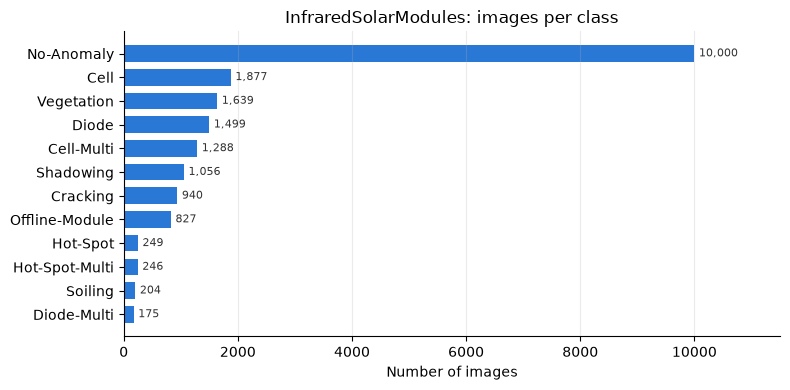

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
c = counts.sort_values()
ax.barh(c.index, c.values, color="#2a78d6", height=0.7)
for y, v in enumerate(c.values):
    ax.text(v + 80, y, f"{v:,}", va="center", fontsize=8, color="#333")
ax.set_xlabel("Number of images"); ax.set_title("InfraredSolarModules: images per class")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.25)
ax.set_xlim(0, 11500)
plt.tight_layout(); plt.savefig("fig_class_distribution.png", dpi=200)

## 2. Look at the images
Always look at your data before modelling. Each image is **40 × 24 pixels, 8-bit grayscale** (values 0–255): bright = hot.

⚠️ **Important for power-loss estimation:** these are *JPEG gray levels, not temperatures in °C.* Each image was contrast-stretched on its own, so gray level 200 in one image is not the same temperature as 200 in another. We therefore **cannot compute ΔT in kelvin** from this dataset. For that we need *radiometric* images (see the meeting notes).

Image shape: (40, 24)


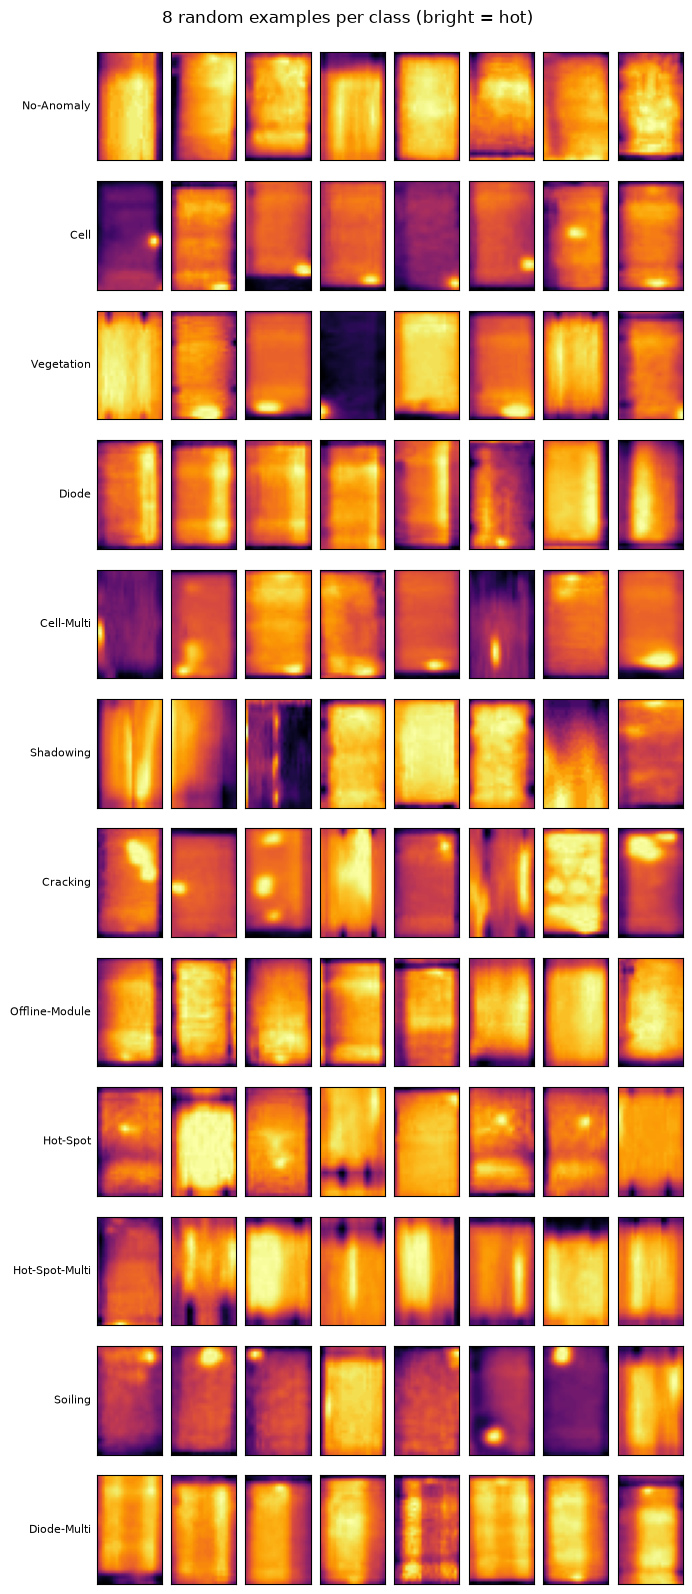

In [4]:
def load_img(path):
    # returns a float array in [0, 1], shape (40, 24)
    return np.asarray(Image.open(DATA_DIR / path), dtype=np.float32) / 255.0

classes = counts.index.tolist()
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(classes), 8, figsize=(7, 16))
for r, cls in enumerate(classes):
    paths = df[df.label == cls].path.values
    for k, p in enumerate(rng.choice(paths, 8, replace=False)):
        ax = axes[r, k]; ax.imshow(load_img(p), cmap="inferno"); ax.set_xticks([]); ax.set_yticks([])
    axes[r, 0].set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=8)
plt.suptitle("8 random examples per class (bright = hot)", y=0.995)
plt.tight_layout(); plt.savefig("fig_examples.png", dpi=200)
print("Image shape:", load_img(df.path[0]).shape)

**What to notice (and say in your meeting):**
* `Cell` = one small hot square; `Cell-Multi` = several.
* `Diode` = one long **third** of the module is warmer. In a typical 60-cell module there are 3 bypass diodes, each protecting one third (a "substring"). When a diode is activated, that substring stops producing power and heats up.
* `Offline-Module` = the **whole** module is warmer (it is disconnected or open-circuited, so all absorbed sunlight becomes heat).
* `Vegetation`/`Shadowing` = irregular patterns, often at the module edge.

These observations **are** the feature design in step 4: we measure *how many hot spots*, *how big*, and *which third is hot*.

## 3. Split the data: train / validation / test (70 / 15 / 15)
* **Train**: the model learns from these.
* **Validation**: we use these to *compare models and choose settings*.
* **Test**: touched **only once, at the very end**, to report the final number. If you tune on the test set, your reported result is optimistic (this is called *data leakage*).

`stratify=` keeps the same class proportions in every split, so rare classes like `Diode-Multi` appear in all three.
We save the split to `splits.csv` so the CNN in Notebook 02 uses **exactly the same** images (a fair comparison).

In [5]:
train_df, test_df = train_test_split(df, test_size=0.15, stratify=df.label, random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.15/0.85, stratify=train_df.label, random_state=SEED)
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):6d} images, Diode-Multi = {(d.label=='Diode-Multi').sum()}")

split = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])
split[["id", "path", "label", "split"]].sort_values("id").to_csv("splits.csv", index=False)

train:  14000 images, Diode-Multi = 123
val  :   3000 images, Diode-Multi = 26
test :   3000 images, Diode-Multi = 26


## 4. Feature engineering: describe each image with numbers
A classical model cannot look at a picture; it needs a **feature vector** (a list of numbers). We build ~700 numbers per image in four groups.

**Step 4a: per-image normalisation (preprocessing).** Because every JPEG was contrast-stretched separately, absolute gray values mean little. We convert each pixel to "how many standard deviations hotter than this module's median":
$$z = \frac{I - \text{median}(I)}{\text{std}(I) + \epsilon}$$
This is the gray-level analogue of **ΔT relative to the healthy part of the module**, the quantity IEC TS 62446-3 uses.

| Group | Numbers | Physical meaning |
|---|---|---|
| Hot-spot statistics | 14 | how much hotter the hottest part is, how much area is hot, **how many separate hot blobs** (Cell vs Cell-Multi) |
| Thirds of the module | 6 | mean z of each third along width and length (**Diode** = one third hot, **Offline** = all hot) |
| Row / column profiles | 64 | average temperature along each row and column (shape of the pattern) |
| HOG | ~ 500 | *Histogram of Oriented Gradients*: edge directions, captures shapes such as square cells or straight shadow edges |
| Small image | 240 | the normalised image shrunk to 20 × 12 pixels, so the model can also see the raw pattern |

In [6]:
def extract_features(img):
    eps = 1e-6
    z = (img - np.median(img)) / (img.std() + eps)          # 4a: per-image normalisation

    # --- hot-spot statistics ---
    hot2, hot3 = z > 2, z > 3                                 # pixels > 2 or 3 std above the median
    lab = label(hot2)                                         # connected "blobs" of hot pixels
    areas = sorted([r.area for r in regionprops(lab)], reverse=True) or [0]
    stats = [z.max(), z.min(), np.percentile(z, 90), np.percentile(z, 99),
             img.std(), img.max() - np.median(img),
             hot2.mean(), hot3.mean(),
             lab.max(),                                       # number of hot blobs
             areas[0], areas[1] if len(areas) > 1 else 0,     # largest / 2nd-largest blob size
             np.mean(areas), (z > 1).mean(), (z < -1).mean()]

    # --- thirds of the module (bypass-diode substrings) ---
    thirds_w = [z[:, i*8:(i+1)*8].mean() for i in range(3)]     # 24 px wide  -> 3 x 8
    thirds_h = [z[i*13:(i+1)*13, :].mean() for i in range(3)]   # 40 px long  -> ~3 x 13

    # --- profiles ---
    row_prof, col_prof = z.mean(axis=1), z.mean(axis=0)         # 40 + 24 numbers

    # --- HOG shape descriptor ---
    h = hog(img, orientations=9, pixels_per_cell=(4, 4), cells_per_block=(2, 2))

    # --- small image ---
    small = z.reshape(20, 2, 12, 2).mean(axis=(1, 3)).ravel()   # 2x2 average pooling -> 20x12

    return np.concatenate([stats, thirds_w, thirds_h, row_prof, col_prof, h, small]).astype(np.float32)

f0 = extract_features(load_img(df.path[0]))
print("Feature vector length per image:", len(f0))

Feature vector length per image: 1944


Now compute the features for all 20,000 images (takes about 1 minute).
`X` = feature matrix (one row per image), `y` = the label of each row.

In [7]:
t0 = time.time()
def featurize(d):
    return np.stack([extract_features(load_img(p)) for p in d.path])
X_train, X_val, X_test = featurize(train_df), featurize(val_df), featurize(test_df)
y_train, y_val, y_test = train_df.label.values, val_df.label.values, test_df.label.values
print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape,
      f" ({time.time()-t0:.0f} s)")

X_train: (14000, 1944)  X_val: (3000, 1944)  X_test: (3000, 1944)  (13 s)


## 5. Train and compare three models
| Model | Idea | Why try it |
|---|---|---|
| **Logistic Regression** | draws straight-line (linear) boundaries between classes | the simplest reasonable model: a sanity check |
| **Random Forest** | votes of many decision trees, each asking questions like "is the left third > 0.8?" | handles non-linear rules, robust, little tuning |
| **Gradient Boosting** (`HistGradientBoosting`) | trees built one after another, each fixing the previous one's mistakes | usually the strongest classical model on tabular features |

**Handling imbalance:** `class_weight="balanced"` makes a mistake on a rare class cost more (weight ∝ 1 / class size), so the model cannot ignore `Diode-Multi`.
We choose the winner by **macro-F1 on the validation set**.

In [8]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
        LogisticRegression(max_iter=2000, C=0.5, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample",
        min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=400, learning_rate=0.08,
        class_weight="balanced", early_stopping=True, random_state=SEED),
}
results = {}
for name, m in models.items():
    t0 = time.time(); m.fit(X_train, y_train)
    p = m.predict(X_val)
    results[name] = {"val accuracy": accuracy_score(y_val, p),
                     "val macro-F1": f1_score(y_val, p, average="macro"),
                     "train time (s)": round(time.time() - t0, 1)}
    print(f"{name:20s} acc={results[name]['val accuracy']:.3f}  macroF1={results[name]['val macro-F1']:.3f}")
res_df = pd.DataFrame(results).T.round(3)
res_df

Logistic Regression  acc=0.564  macroF1=0.374
Random Forest        acc=0.681  macroF1=0.417
Gradient Boosting    acc=0.691  macroF1=0.537


,val accuracy,val macro-F1,train time (s)
Logistic Regression,0.564,0.374,3.7
Random Forest,0.681,0.417,21.2
Gradient Boosting,0.691,0.537,94.4


In [9]:
print(res_df.to_string())
best_name = res_df["val macro-F1"].astype(float).idxmax()
best = models[best_name]
print("\nBest model on validation:", best_name)

                     val accuracy  val macro-F1  train time (s)
Logistic Regression         0.564         0.374             3.7
Random Forest               0.681         0.417            21.2
Gradient Boosting           0.691         0.537            94.4

Best model on validation: Gradient Boosting


## 6. Final evaluation on the test set (used once)
* **Precision** of a class: of all images the model *called* "Diode", how many really were Diode.
* **Recall** of a class: of all real "Diode" images, how many the model *found*. For maintenance, **recall of serious faults matters most** (a missed fault = lost energy).
* **F1** = harmonic mean of precision and recall.
* **Confusion matrix:** rows = true class, columns = predicted class. Each row is normalised to 1, so the diagonal is the recall of each class. Off-diagonal cells show *which faults are confused with which*, which is useful to discuss.

In [10]:
p_test = best.predict(X_test)
print(f"TEST  accuracy = {accuracy_score(y_test, p_test):.3f}   macro-F1 = {f1_score(y_test, p_test, average='macro'):.3f}\n")
print(classification_report(y_test, p_test, digits=3))

TEST  accuracy = 0.690   macro-F1 = 0.519

                precision    recall  f1-score   support

          Cell      0.481     0.539     0.508       282
    Cell-Multi      0.361     0.316     0.337       193
      Cracking      0.531     0.603     0.565       141
         Diode      0.843     0.858     0.850       225
   Diode-Multi      0.789     0.577     0.667        26
      Hot-Spot      0.478     0.297     0.367        37
Hot-Spot-Multi      0.372     0.432     0.400        37
    No-Anomaly      0.867     0.825     0.846      1500
Offline-Module      0.385     0.556     0.455       124
     Shadowing      0.535     0.532     0.533       158
       Soiling      0.300     0.097     0.146        31
    Vegetation      0.532     0.581     0.555       246

      accuracy                          0.690      3000
     macro avg      0.540     0.518     0.519      3000
  weighted avg      0.698     0.690     0.692      3000



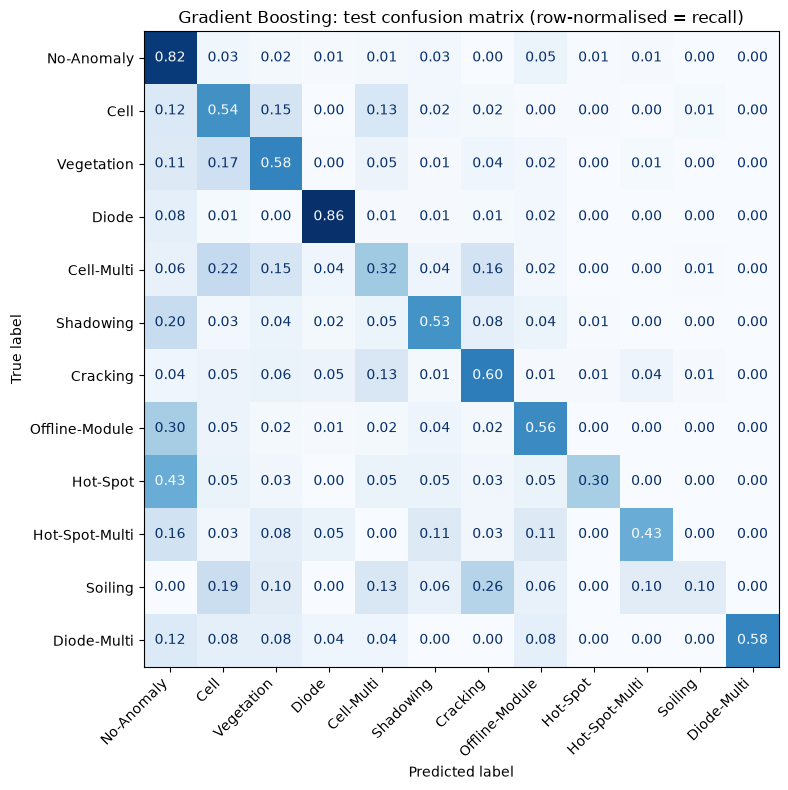

In [11]:
order = counts.index.tolist()
cm = confusion_matrix(y_test, p_test, labels=order, normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=order).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
ax.set_title(f"{best_name}: test confusion matrix (row-normalised = recall)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.savefig("fig_confusion_matrix.png", dpi=200)

### Reading the confusion matrix (discussion points)
* **Diode (0.85 recall) is easy**: a hot third of the module is a very clear pattern, and the "thirds" features capture it directly.
* **Cell vs Cell-Multi vs Vegetation are confused** with each other: all are small hot areas; the difference is count and shape, which is hard at 40 × 24 pixels.
* **Offline-Module → No-Anomaly (27 %)**: an important *physical* insight. An offline module is uniformly hot, but each JPEG was contrast-stretched by itself, so a uniformly hot module looks "normal" when seen alone. Detecting it properly needs **absolute temperature (radiometric data)** or **comparison with neighbouring modules** in the full drone image. This is a strong argument for the segmentation + radiometric part of the project.
* **Soiling (0.10) and Hot-Spot (0.27)** are the rarest classes (≈ 200 images) → the model has too few examples. Remedies: data augmentation, the CNN, or merging classes.

### Binary view: "is there any fault?"
For an inspection company the first question is simply *fault or not*. We merge the 11 fault classes into one and check how many faulty modules are found (recall) and how many alarms are false.

In [12]:
yt_bin = np.where(y_test == "No-Anomaly", "OK", "Fault")
yp_bin = np.where(p_test == "No-Anomaly", "OK", "Fault")
print(classification_report(yt_bin, yp_bin, digits=3))

              precision    recall  f1-score   support

       Fault      0.833     0.874     0.853      1500
          OK      0.867     0.825     0.846      1500

    accuracy                          0.849      3000
   macro avg      0.850     0.849     0.849      3000
weighted avg      0.850     0.849     0.849      3000



## 7. First version of power-loss estimation (class-based)
Because this dataset has no temperatures, version 1 estimates loss from the **electrical topology of the module**:
a standard 60-cell module has **3 substrings, each protected by one bypass diode**.

| Class | Estimated power loss of the module | Reason |
|---|---|---|
| No-Anomaly | 0 % | healthy |
| Diode | ≈ 33 % | 1 of 3 substrings bypassed |
| Diode-Multi | ≈ 67 % | 2 of 3 substrings bypassed |
| Offline-Module | 100 % | module produces nothing |
| Cell, Cell-Multi, Hot-Spot(-Multi), Cracking, Soiling, Shadowing, Vegetation | **not fixed yet** | depends on severity (ΔT, shaded area) → needs radiometric data or literature values (to discuss with advisor) |

Below we apply only the physically certain values and compare **true** vs **predicted** total loss on the test set, to show how classification errors turn into power-estimation errors.
Assumed module rating: 330 W (a typical 60-cell module; change to the real plant's value).

In [13]:
P_MODULE = 330  # W, assumption
LOSS = {"No-Anomaly": 0.0, "Diode": 1/3, "Diode-Multi": 2/3, "Offline-Module": 1.0}   # fraction of P_MODULE

known = np.isin(y_test, list(LOSS))          # only modules whose TRUE class has a certain loss value
true_loss = np.array([LOSS[c] for c in y_test[known]]) * P_MODULE
pred_loss = np.array([LOSS.get(c, np.nan) for c in p_test[known]]) * P_MODULE
ok = ~np.isnan(pred_loss)                    # predicted class also has a known value
print(f"Test modules with a certain loss value: {known.sum()}")
print(f"True total loss      : {true_loss.sum()/1000:.2f} kW")
print(f"Predicted total loss : {np.nansum(pred_loss)/1000:.2f} kW  "
      f"({(~ok).sum()} modules predicted as a class without a loss value yet)")
for c in ["Diode", "Diode-Multi", "Offline-Module"]:
    t = (y_test == c).sum(); pp = (p_test == c).sum()
    print(f"  {c:15s} true count = {t:4d}  predicted count = {pp:4d}")

Test modules with a certain loss value: 1875
True total loss      : 71.39 kW
Predicted total loss : 77.33 kW  (201 modules predicted as a class without a loss value yet)
  Diode           true count =  225  predicted count =  229
  Diode-Multi     true count =   26  predicted count =   19
  Offline-Module  true count =  124  predicted count =  179


## 8. Summary and next steps
* This notebook is a **complete classical baseline**: preprocessing (per-image normalisation), physics-motivated features, three models, honest test evaluation, and a first class-based power-loss estimate.
* **Next (Notebook 02):** a CNN in PyTorch trained on the *same split*. It learns its own features from the pixels, and must beat this baseline's macro-F1.
* **Then:** full drone frames → module segmentation (block 3), and radiometric data → ΔT-based power loss (block 5).